In [100]:
# This notebook is my first attempt to implement a general multiple linear regression algorithm.

# The general program flow is as follows:
# - Load the training set into x_train and y_train
# - initialize starting weights and b with values 0
# - load parameters batch size, number of iterations, learning rate
# - calculate predictions y_hat, calculate loss, adapt weights through gradient descent




In [101]:
import numpy as np
import matplotlib.pyplot as plt

In [102]:
#LOAD DATA
data = np.loadtxt("houses.txt", delimiter=',')
x_train = data[:,:4]
y_train = data[:,4]

# x_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
# y_train = np.array([460, 232, 178])

# print(data.shape)
print(f"{x_train.shape=}, {y_train.shape=}")

x_train.shape=(100, 4), y_train.shape=(100,)


In [103]:
#Set Hyperparameters
batch_size = 0  # 0...whole dataset as batch, batch functionality to be implemented later
iterations = 100
learning_rate = .5

In [104]:
# Data normalization using Z scores:
x_std = x_train.std(axis=0)
x_mean = x_train.mean(axis=0)
x_tn = (x_train - x_mean) / x_std

In [105]:
#Initialization:
w = np.zeros(len(x_train[0]))   # weights per feature
b = 0   # bias
m = len(x_train)    # number examples in training set
n = len(x_train[0]) # number features
#print(w)


In [ ]:
def gradient_descent(x, y, w, b):
    y_hat =  x @ w + b
    norm_err = (y_hat - y) / m     # m sized array containing the loss per example divided by m: 1/m * (w @ x(i) + b - y(i))
    gradient_b = np.sum(norm_err)
    gradient_w = norm_err @ x
    #print(f"{y_hat=}\n{gradient_b=}\n{gradient_w=}\n")
    return gradient_w, gradient_b


def calc_loss(x, y, w, b):
    y_hat =  x @ w + b
    abs_err = y_hat - y
    sum_loss = np.sum(abs_err ** 2)
    return sum_loss / (2 * m)

def predict(x, w, b):
    x_n = (x - x_mean) / x_std
    y_hat = x_n @ w + b
    return y_hat


In [107]:
# Formulae:
# y_hat = w @ x + b
# loss = 1/(2m) * sum(y_hat - y)**2 for all y, y_hat in batch
# gradient for w[j] = dL / dw[j] = 1/m * sum over all i for { [w @ x(i) + b - y(i)] * x(i,j)}
# gradient for b    = dL / db    = 1/m * sum over all i for {  w @ x(i) + b - y(i)}
# update: w(j),b -=  learning_rate * gradient(j,b)

loss_history = []
for i in range(iterations):
    gradient_w, gradient_b = gradient_descent(x_tn, y_train, w, b)
    w -= learning_rate * gradient_w
    b -= learning_rate * gradient_b
    loss_history.append(calc_loss(x_tn, y_train, w, b))
    if i % (iterations // 10) == 0:
        loss = calc_loss(x_tn, y_train, w, b)
        print(f"{w=}\n{b=}\n{loss=}\n\n")
    





w=array([ 44.57940068,  15.09567464,  16.63734391, -29.96632512])
b=np.float64(181.11975999999996)
loss=np.float64(18137.030750082115)


w=array([ 99.32875596, -15.99604795, -26.13564391, -39.85893658])
b=np.float64(362.062645234375)
loss=np.float64(253.53916300377986)


w=array([108.76325689, -20.54539748, -31.62726615, -38.13814077])
b=np.float64(362.2393472707367)
loss=np.float64(220.61810421483722)


w=array([110.31016843, -21.32024177, -32.49242119, -37.83857611])
b=np.float64(362.23951983131906)
loss=np.float64(219.7356491614899)


w=array([110.56367083, -21.44813985, -32.63315965, -37.78909489])
b=np.float64(362.2395199998353)
loss=np.float64(219.71195551038923)


w=array([110.6052109 , -21.46912522, -32.65619081, -37.78097528])
b=np.float64(362.23951999999986)
loss=np.float64(219.71131931852713)


w=array([110.61201776, -21.47256475, -32.65996384, -37.77964444])
b=np.float64(362.23952)
loss=np.float64(219.71130223628867)


w=array([110.61313315, -21.47312838, -32.66058207, -37.

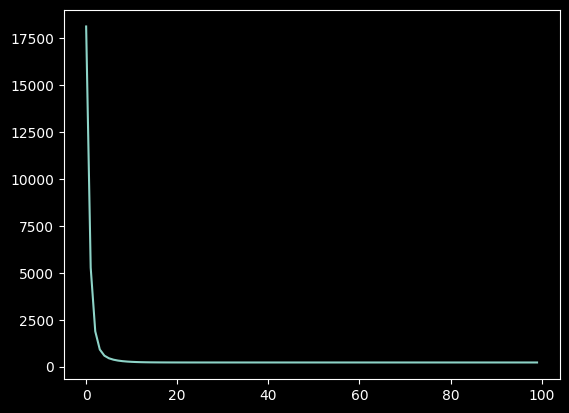

In [108]:
plt.plot(loss_history)

In [109]:
for i in range(20):
    print(f"x_train: {x_train[i]}")
    print(f"y_train: {y_train[i]}")

    print(predict(x_train[i],w,b))

x_train: [952.   2.   1.  65.]
y_train: 271.5
248.65591791128554
x_train: [1.244e+03 3.000e+00 1.000e+00 6.400e+01]
y_train: 300.0
295.5804587414807
x_train: [1947.    3.    2.   17.]
y_train: 509.8
485.8168950129687
x_train: [1725.    3.    2.   42.]
y_train: 394.0
389.61035743793764
x_train: [1959.    3.    2.   15.]
y_train: 540.0
491.9676274057367
x_train: [1.314e+03 2.000e+00 1.000e+00 1.400e+01]
y_train: 415.0
420.5281137777613
x_train: [864.   2.   1.  66.]
y_train: 230.0
223.57450479038363
x_train: [1.836e+03 3.000e+00 1.000e+00 1.700e+01]
y_train: 560.0
523.3162620032441
x_train: [1.026e+03 3.000e+00 1.000e+00 4.300e+01]
y_train: 294.0
267.8450983529337
x_train: [3.194e+03 4.000e+00 2.000e+00 8.700e+01]
y_train: 718.2
685.0044700798883
x_train: [788.   2.   1.  80.]
y_train: 200.0
182.66630944827722
x_train: [1200.    2.    2.   17.]
y_train: 302.0
318.2507980352216
x_train: [1.557e+03 2.000e+00 1.000e+00 1.800e+01]
y_train: 468.0
479.88048470986274
x_train: [1.43e+03 3.00e+00